# 1

### Nota: 10

Este proyecto tiene como objetivo construir y entrenar una red neuronal feed-forward utilizando PyTorch para predecir las puntuaciones de los estudiantes en función de las horas de estudio, utilizando el 'Students Score Dataset'. Los participantes aplicarán técnicas de preprocesamiento de datos, entrenarán una red neuronal, y evaluarán el rendimiento del modelo utilizando métricas de regresión como R2, MAE, y RMSE.

In [169]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk
import torch
import torch.nn as nn

work_dir = "../media/2_lab1/1/"
file_dir = "student_scores.csv"
seed = 112211

In [170]:
data = pd.read_csv(work_dir + file_dir)

In [171]:
data.head()

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


In [172]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   25 non-null     float64
 1   Scores  25 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 532.0 bytes


Tenemos dos columnas. *Hours* es el número de horas que el alumno ha estudiado, y *Scores* la nota que ha sacado ese alumno. Estamos ante un problema de regresión lineal (un poco overkill usar una red neuronal para este caso). Respectivamente las denominamos como $X$ e $y$

In [173]:
X = data.Hours
y = data.Scores

Hacemos la división a conjuntos de entrenamiento y de prueba.

In [174]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = seed)

Definimos ahora una red neuronal feed forward.

In [175]:
class ffnet(nn.Module):
    def __init__(
            self,
            input_size: int,
            output_size: int
    ):       
        super().__init__()
        self.h1 = nn.Linear(input_size, 64)
        self.relu1 = nn.ReLU()
        self.h2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.out = nn.Linear(32, output_size)


    def forward(
            self,
            x
    ):
        x = self.h1(x)
        x = self.relu1(x)
        x = self.h2(x)
        x = self.relu2(x)
        x = self.out(x)
        return x
        

Hay que transformar los datos a tensores.

In [176]:
X_train = torch.from_numpy(X_train.to_numpy(dtype=np.float32)).reshape(-1, 1)
X_test = torch.from_numpy(X_test.to_numpy(dtype=np.float32)).reshape(-1, 1)
y_train = torch.from_numpy(y_train.to_numpy(dtype=np.float32)).reshape(-1, 1)
y_test = torch.from_numpy(y_test.to_numpy(dtype=np.float32)).reshape(-1, 1)

La función de pérdida será un MSE, con optimizador Adam, y 200 epochs

In [177]:
model = ffnet(1, 1)

epochs = 200
loss = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters())

Procedemos al entrenamiento

In [178]:
hist = []
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    pred = model(X_train)
    l = loss(pred, y_train)
    l.backward()
    optimizer.step()
    hist.append(l.detach().numpy())
    print(f"Epoch {epoch + 1} finalizado -> MSE : {l}")

Epoch 1 finalizado -> MSE : 3372.6376953125
Epoch 2 finalizado -> MSE : 3355.536865234375
Epoch 3 finalizado -> MSE : 3338.525634765625
Epoch 4 finalizado -> MSE : 3321.69580078125
Epoch 5 finalizado -> MSE : 3304.9111328125
Epoch 6 finalizado -> MSE : 3288.130615234375
Epoch 7 finalizado -> MSE : 3272.197021484375
Epoch 8 finalizado -> MSE : 3256.28955078125
Epoch 9 finalizado -> MSE : 3240.18798828125
Epoch 10 finalizado -> MSE : 3223.5498046875
Epoch 11 finalizado -> MSE : 3206.4775390625
Epoch 12 finalizado -> MSE : 3189.24658203125
Epoch 13 finalizado -> MSE : 3172.47509765625
Epoch 14 finalizado -> MSE : 3155.9560546875
Epoch 15 finalizado -> MSE : 3139.3369140625
Epoch 16 finalizado -> MSE : 3122.56494140625
Epoch 17 finalizado -> MSE : 3105.61279296875
Epoch 18 finalizado -> MSE : 3088.4736328125
Epoch 19 finalizado -> MSE : 3071.41845703125
Epoch 20 finalizado -> MSE : 3055.399658203125
Epoch 21 finalizado -> MSE : 3039.74951171875
Epoch 22 finalizado -> MSE : 3024.0322265625


Veamos la evolución de la función de pérdida

Text(0, 0.5, 'MSE')

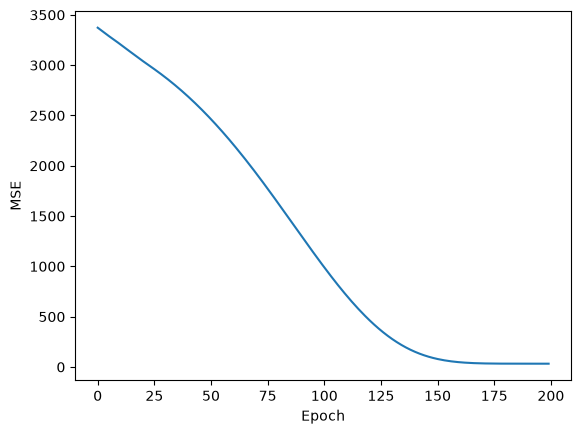

In [179]:
plt.plot(hist)
plt.xlabel("Epoch")
plt.ylabel("MSE")

Vamos a evaluar el modelo con unas cuantas métricas: R2, MAE y RMSE

In [180]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

y_pred = model(X_test).detach().numpy()
y_test = y_test.detach().numpy()

R2 = r2_score(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)
RMSE = root_mean_squared_error(y_test, y_pred)

print(f"R2: {R2}")
print(f"MAE: {MAE}")
print(f"RMSE: {RMSE}")

R2: 0.926307737827301
MAE: 4.767855167388916
RMSE: 5.898965358734131
